In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
from sklearn.preprocessing import StandardScaler

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
random_state = 42
np.random.seed(random_state)

In [7]:
data = pd.read_csv('auto-mpg.csv', na_values='?')
data.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(4), int64(4), str(1)
memory usage: 28.1 KB


In [9]:
df_clean = (data.drop(columns=['origin', 'car name', 'cylinders'])
            .dropna()
            .reset_index(drop=True))

df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   displacement  392 non-null    float64
 2   horsepower    392 non-null    float64
 3   weight        392 non-null    int64  
 4   acceleration  392 non-null    float64
 5   model year    392 non-null    int64  
dtypes: float64(4), int64(2)
memory usage: 18.5 KB


In [10]:
TARGET = 'mpg'
quantity_features = ['displacement', 'horsepower', 'weight', 'acceleration', 'model year']

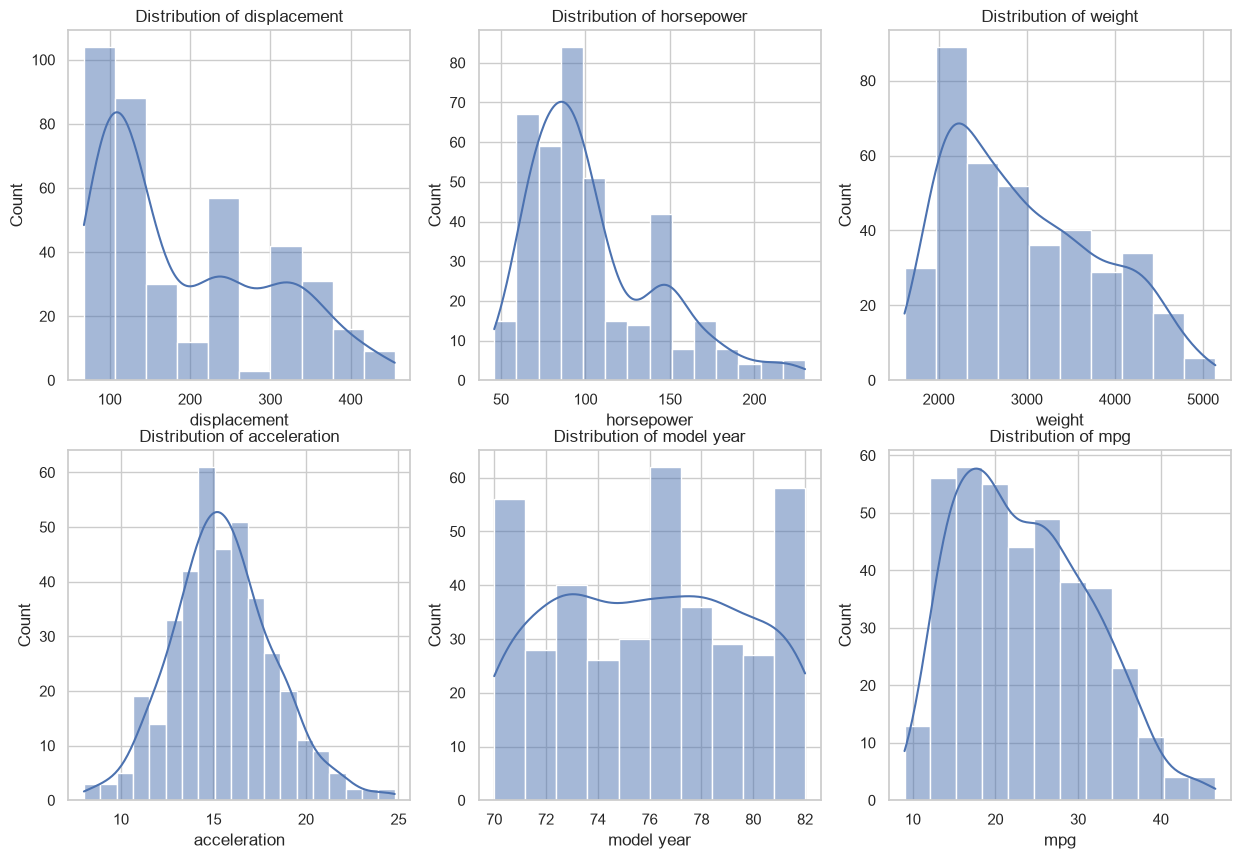

In [11]:
cols = quantity_features + [TARGET]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
for i,c in enumerate(cols):
    sns.histplot(df_clean[c], ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {c}')


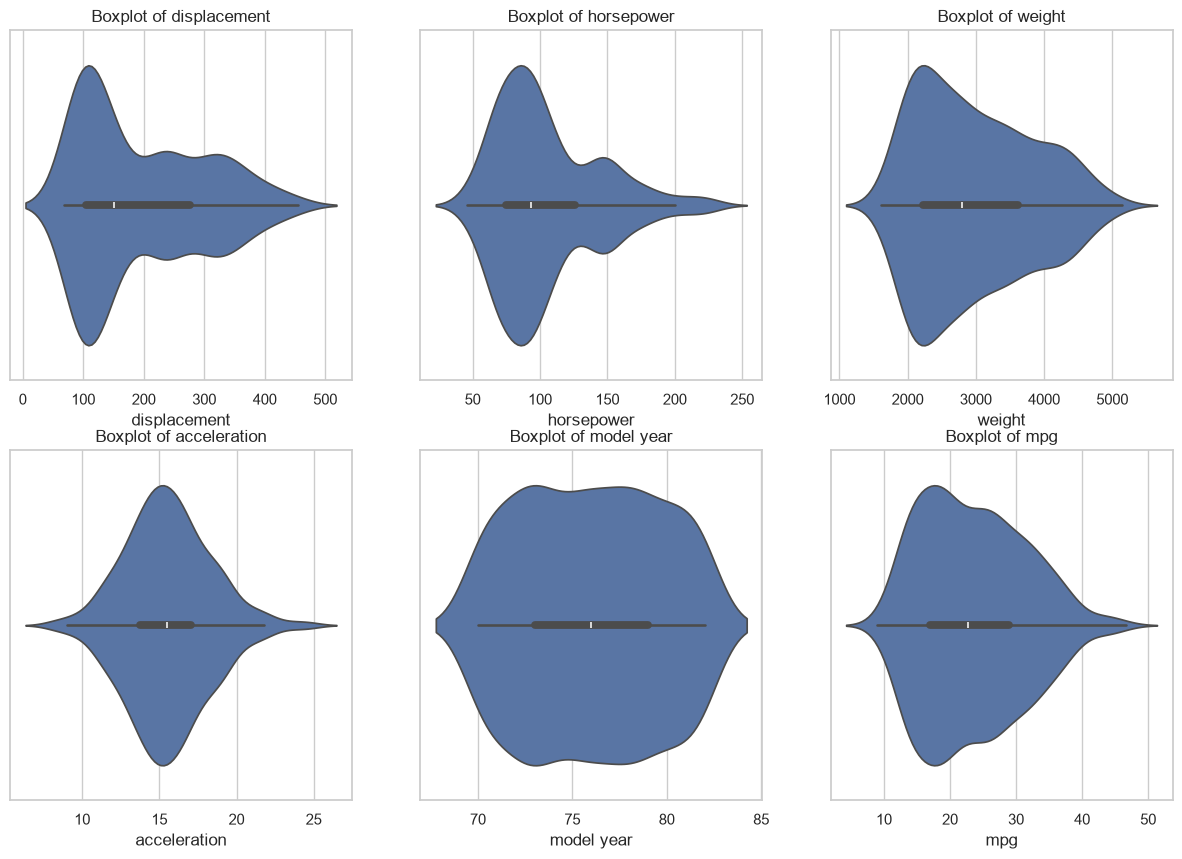

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
for i,c in enumerate(cols):
    sns.violinplot(x=df_clean[c], ax=axes[i])
    axes[i].set_title(f'Boxplot of {c}')


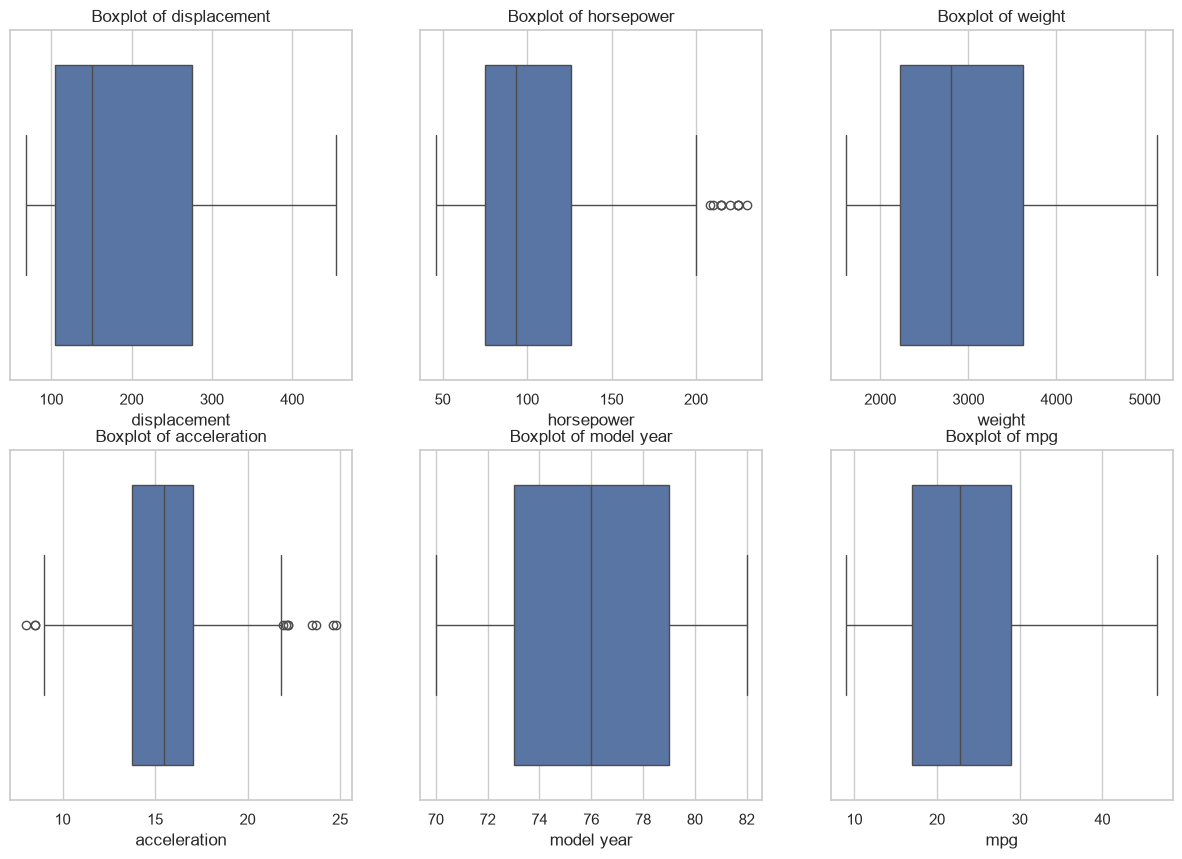

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
for i,c in enumerate(cols):
    sns.boxplot(x=df_clean[c], ax=axes[i])
    axes[i].set_title(f'Boxplot of {c}')

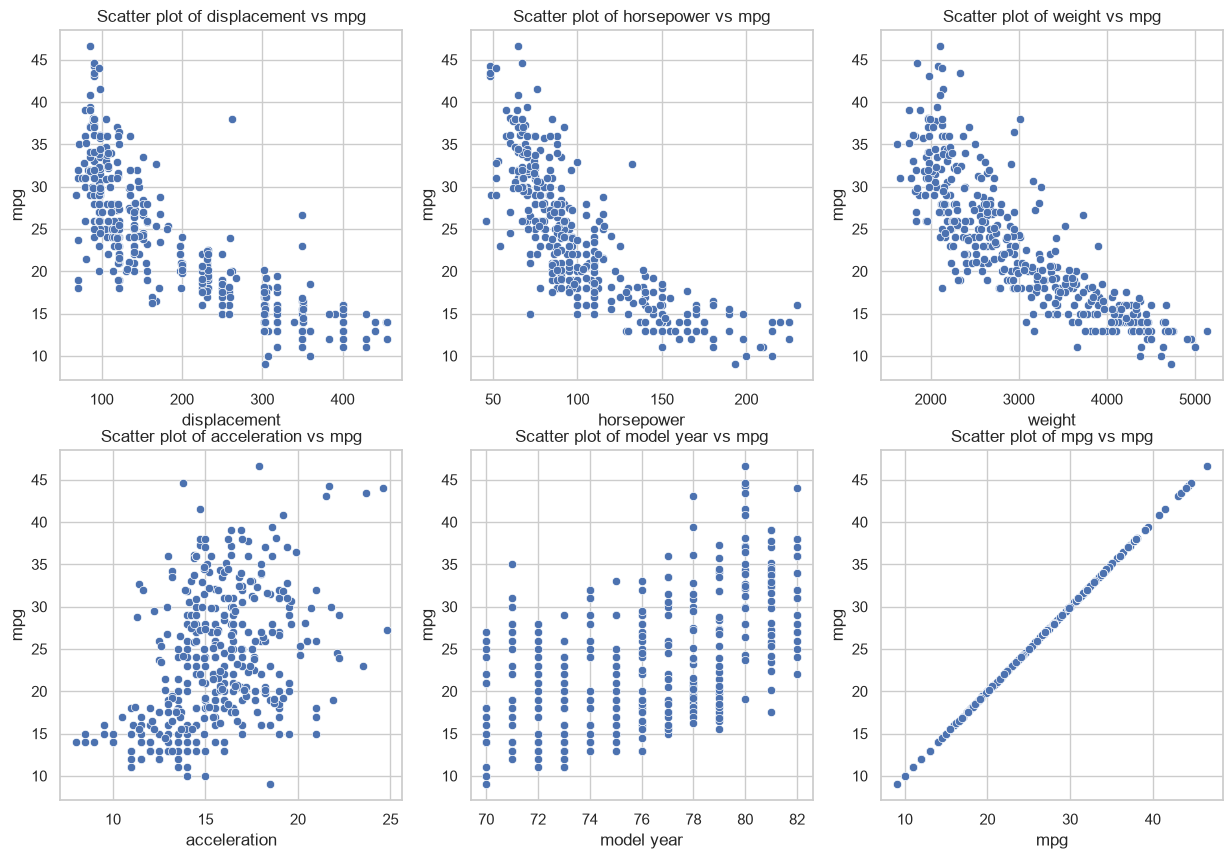

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
for i,c in enumerate(cols):
    sns.scatterplot(x=df_clean[c], y=df_clean[TARGET], ax=axes[i])
    axes[i].set_title(f'Scatter plot of {c} vs {TARGET}')
    

In [15]:
for c in cols[:4]:
    df_clean[c] = pd.to_numeric(df_clean[c], errors='coerce')

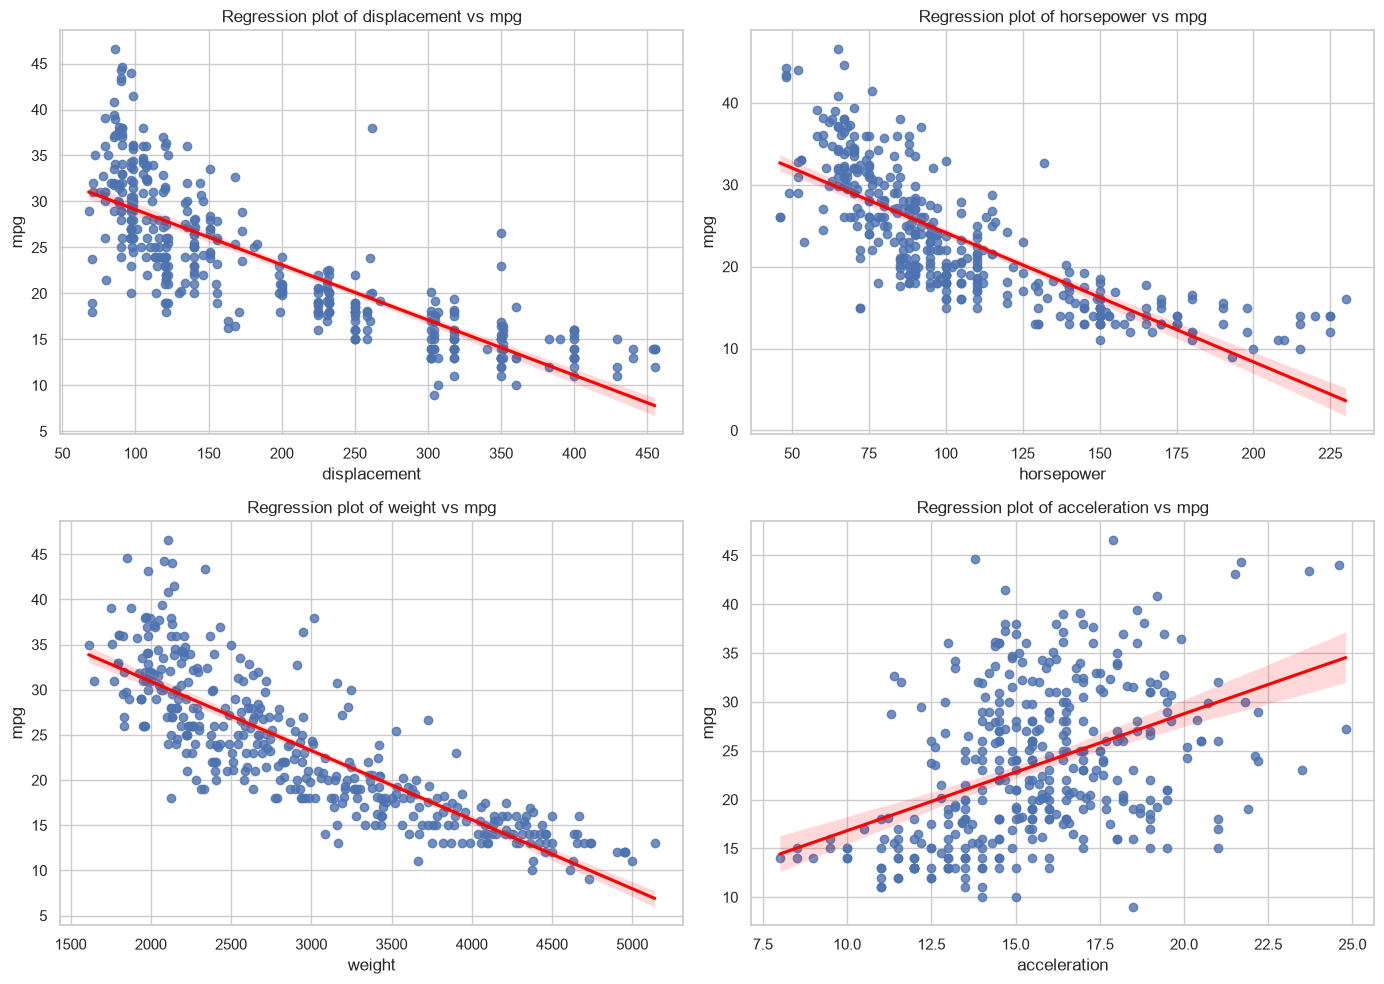

In [16]:
fig, axes = plt.subplots(2,2, figsize=(14, 10))
axes = axes.ravel()
for i, c in enumerate(cols[:4]):
    sns.regplot(data=df_clean, x=c, y=TARGET, ax=axes[i],line_kws={"color": "red"})
    axes[i].set_title(f'Regression plot of {c} vs {TARGET}'
    )
plt.tight_layout()
plt.show()

,mpg,displacement,horsepower,weight,acceleration,model year
mpg,1.000000,-0.805127,-0.778427,-0.832244,0.423329,0.580541
displacement,-0.805127,1.000000,0.897257,0.932994,-0.543800,-0.369855
horsepower,-0.778427,0.897257,1.000000,0.864538,-0.689196,-0.416361
weight,-0.832244,0.932994,0.864538,1.000000,-0.416839,-0.309120
acceleration,0.423329,-0.543800,-0.689196,-0.416839,1.000000,0.290316
model year,0.580541,-0.369855,-0.416361,-0.309120,0.290316,1.000000


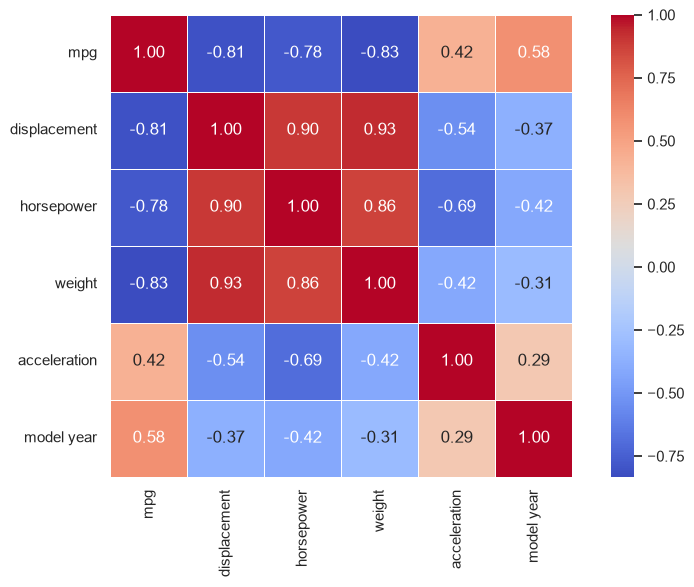

In [17]:
plt.figure(figsize=(10, 6))
sns.heatmap(df_clean.corr(),annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
df_clean.corr()

In [18]:
X = df_clean[quantity_features]
Y = df_clean[TARGET]

train_size = 0.8
test_size = 0.2



In [19]:
train_X, test_X, train_Y, test_Y = train_test_split(X, Y, train_size=train_size, test_size=test_size, random_state=random_state)

In [20]:
model = LinearRegression()
model.fit(train_X, train_Y)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0. ,-0. ,-0.01, 0.06, 0.76]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','model year']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-15.35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5


In [21]:
y_pred = model.predict(test_X)
y_pred

array([25.94069501, 26.26450538, 32.98786453, 26.87783614, 29.37807295,
       29.09548123,  7.55404471, 29.24471794, 20.87742308, 28.97453954,
       12.44003156, 23.83004234, 16.42879648, 28.20431753, 22.15663498,
       30.86198437, 21.23372787, 31.63328468, 27.87351859, 29.74308445,
       19.89840552, 34.38272498, 34.01200188, 15.11483297, 28.81019922,
       26.00229443, 20.78146351, 16.63110094, 28.50671906, 23.7892342 ,
       12.82227894, 23.59518505, 21.52416864, 29.84428245, 10.97143451,
       34.72151338, 10.92781666, 26.27012067, 11.67034473,  7.72060566,
       12.85165705, 27.83199225, 34.74004299, 26.49475409, 11.35607445,
        8.96782253, 17.62496372, 31.45269112, 25.36189045, 30.40797077,
       11.61355918, 25.13507671, 24.45658803, 33.46674915, 28.90743505,
       17.76559828, 20.94781706, 23.16622304, 23.10630798, 24.60964392,
        7.5154241 , 22.92119621, 27.43800545, 23.0507875 , 28.08133258,
       28.67320091, 26.77890855, 29.6346114 , 22.40894377,  9.25

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [23]:
numeric_features = ['displacement', 'horsepower', 'weight', 'acceleration']
categorical_features = ['model year','origin']

df_full = (data
    .drop(columns=['car name'])
    .dropna()
    .reset_index(drop=True)
)

df_full

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,1
1,15.0,8,350.0,165.0,3693,11.5,70,1
2,18.0,8,318.0,150.0,3436,11.0,70,1
3,16.0,8,304.0,150.0,3433,12.0,70,1
4,17.0,8,302.0,140.0,3449,10.5,70,1
...,...,...,...,...,...,...,...,...
387,27.0,4,140.0,86.0,2790,15.6,82,1
388,44.0,4,97.0,52.0,2130,24.6,82,2
389,32.0,4,135.0,84.0,2295,11.6,82,1
390,28.0,4,120.0,79.0,2625,18.6,82,1


In [24]:
X_full = df_full[numeric_features + categorical_features]
y_full = df_full[TARGET]

In [25]:
train_X_full, test_X_full, train_Y_full, test_Y_full = train_test_split(X_full, y_full, train_size=train_size, test_size=test_size, random_state=random_state)

In [26]:
#preprocesser
full_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

In [27]:
full_model = Pipeline(steps=[
    ('preprocessor', full_preprocessor),
    ('regressor', LinearRegression())
])

In [28]:
#training with preprocesseing

full_model.fit(train_X_full, train_Y_full)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['displacement','horsepower','weight','acceleration','model year','origin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [29]:
full_model.named_steps["regressor"].coef_

array([ 1.17681029, -0.97501827, -4.94235096,  0.08234391, -3.39547735,
       -2.06756467, -3.20091429, -3.81336269, -1.25201445, -2.60502942,
       -1.28542196,  0.23567337,  0.21607276,  1.93099054,  6.1057381 ,
        3.79938354,  5.33192652, -1.69757801,  0.79887395,  0.89870406])

In [30]:
fetures_name = full_model.named_steps["preprocessor"].get_feature_names_out()
full_coefficients = pd.DataFrame(
    {
        "feature": fetures_name,
        "coefficient": full_model.named_steps["regressor"].coef_
    }
)
full_coefficients.sort_values(by="coefficient", ascending=False, inplace=True)
full_coefficients

,feature,coefficient
14,cat__model year_80,6.105738
16,cat__model year_82,5.331927
15,cat__model year_81,3.799384
13,cat__model year_79,1.930991
0,num__displacement,1.176810
19,cat__origin_3,0.898704
18,cat__origin_2,0.798874
11,cat__model year_77,0.235673
12,cat__model year_78,0.216073
3,num__acceleration,0.082344


In [31]:
y_pred = full_model.predict(test_X_full)
y_pred

array([26.45774061, 25.35152281, 32.38986704, 26.46264931, 28.95300882,
       28.48463543, 10.74725033, 29.4110397 , 18.97410447, 27.97636493,
       13.966289  , 23.72563037, 16.91706394, 27.05915677, 21.752954  ,
       29.78977873, 20.98846515, 32.55847913, 26.17797021, 33.65987217,
       20.39885966, 35.97599732, 34.66863079, 16.69275604, 29.52144312,
       24.81187106, 21.66576959, 18.21192951, 27.93773534, 24.66811143,
       12.13897411, 22.35519051, 21.18580384, 31.08691074, 11.17126733,
       36.17368431, 11.96756018, 24.03922835, 12.04317875,  8.64656965,
       13.45003151, 28.58896286, 36.11625474, 27.43271678, 10.78207719,
        8.34337818, 19.53279851, 31.78349104, 22.5683485 , 29.65142494,
       14.1522664 , 25.4904829 , 24.5441845 , 34.94658866, 29.04363368,
       18.21210805, 19.19164813, 20.98590276, 24.58152852, 26.87419057,
        6.98746506, 21.60105684, 25.63780552, 22.29244819, 27.73072377,
       28.07966861, 24.19224917, 28.32596371, 21.20109708, 11.35

In [32]:
mse = mean_squared_error(test_Y_full, y_pred)
rmse_value = rmse(test_Y_full, y_pred)
mae = mean_absolute_error(test_Y_full, y_pred)

In [33]:
mse


8.334983420711874

In [34]:
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_value:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Mean Squared Error (MSE): 8.3350
Root Mean Squared Error (RMSE): 2.8870
Mean Absolute Error (MAE): 2.1847


In [35]:
#joblib --> Classical ML
#.pt --> pytorch model
#.h5 --> keras model
#.tf --> tensorflow model


In [36]:
from joblib import dump, load
import joblib

In [37]:
model_path = "mlr_mpg.joblib"
model_path

'mlr_mpg.joblib'

In [38]:
joblib.dump(full_model, model_path)

['mlr_mpg.joblib']

In [40]:
inferenced_model = joblib.load(model_path)
print(inferenced_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['displacement', 'horsepower',
                                                   'weight', 'acceleration']),
                                                 ('cat', OneHotEncoder(),
                                                  ['model year', 'origin'])])),
                ('regressor', LinearRegression())])


In [42]:
sample_input = test_X_full.head(5).copy(deep=True)
sample_input

,displacement,horsepower,weight,acceleration,model year,origin
78,96.0,69.0,2189,18.0,72,2
274,121.0,115.0,2795,15.7,78,2
246,91.0,60.0,1800,16.4,78,3
55,91.0,70.0,1955,20.5,71,1
387,140.0,86.0,2790,15.6,82,1


In [43]:
inference_output = inferenced_model.predict(sample_input)
inference_output

array([26.45774061, 25.35152281, 32.38986704, 26.46264931, 28.95300882])

In [44]:
sample_input.info()

<class 'pandas.DataFrame'>
Index: 5 entries, 78 to 387
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  5 non-null      float64
 1   horsepower    5 non-null      float64
 2   weight        5 non-null      int64  
 3   acceleration  5 non-null      float64
 4   model year    5 non-null      int64  
 5   origin        5 non-null      int64  
dtypes: float64(3), int64(3)
memory usage: 280.0 bytes
